# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

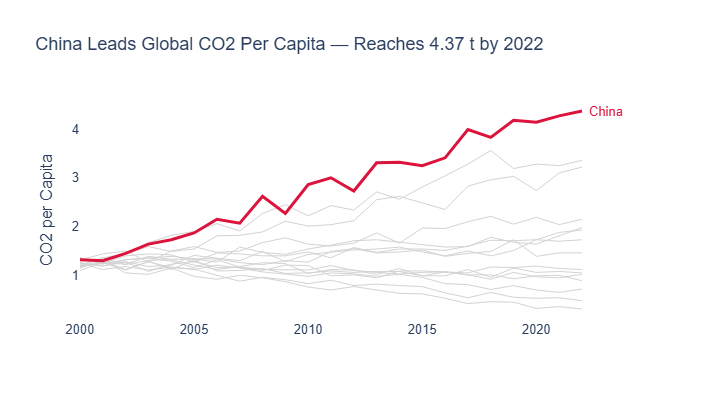

In [86]:
# Task 1: CO2 per capita — China highlighted
highlight = 'China'

fig = px.line(
    df, x='Year', y='CO2_per_capita',
    line_group='Country',
    color=df['Country'].where(df['Country'] == highlight, 'Other'),
    color_discrete_map={highlight: 'crimson', 'Other': 'lightgrey'},
    hover_name='Country',
    labels={'CO2_per_capita': 'CO2 per Capita'},
    title='China Leads Global CO2 Per Capita — Reaches 4.37 t by 2022',
    template='plotly_white', 
    height=400
)

fig.update_traces(line_width=1)                              
fig.update_traces(line_width=3, selector={'name': highlight})
fig.update_traces(hovertemplate='<b>%{hovertext}</b><br>Year=%{x}<br>CO2 per Capita=%{y}<extra></extra>')

last = df[(df['Country'] == highlight) & (df['Year'] == df['Year'].max())].iloc[0]
fig.add_annotation(
    x=last['Year'], y=last['CO2_per_capita'], text=highlight,
    showarrow=False, xanchor='left', xshift=5, font_color='crimson')

fig.update_layout(
    showlegend=False,
    yaxis=dict(showgrid=False),
    xaxis=dict(showgrid=False, title=''),
    font=dict(family='Arial', size=13)
)
fig.show()


---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

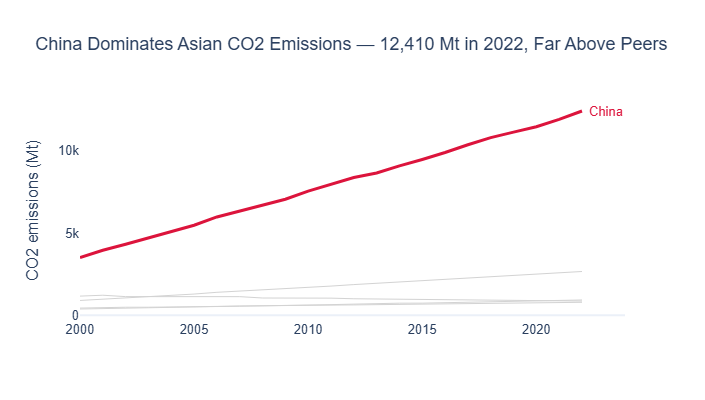

In [98]:
# Task 2 
# YOUR CODE HERE

# Task 2: CO2 emissions for Asian countries, with China highlighted

asia = df[df['Region'] == 'Asia']
highlight = 'China'

# Draw every Asian country in light grey first
fig = px.line(
    asia, x='Year', y='CO2_Mt', 
    line_group='Country',
    color=asia['Country'].where(asia['Country'] == highlight, 'Other'),
    color_discrete_map={highlight: 'crimson', 'Other': 'lightgrey'},
    category_orders={'color': ['Other', highlight]},
    hover_name='Country',
    labels={'CO2_Mt': 'CO2 emissions (Mt)'},
    title="China Dominates Asian CO2 Emissions — 12,410 Mt in 2022, Far Above Peers",
    template='plotly_white',
    height=400
)

# Add China as the coloured line
china = asia[asia['Country'] == highlight]

fig.update_traces(line_width=1)
fig.update_traces(line_width=3, selector={'name': highlight})
fig.update_traces(hovertemplate='<b>%{hovertext}</b><br>Year=%{x}<br>CO2 emissions (Mt)=%{y:,.0f}<extra></extra>')

# Label China at the end of its line
last = asia[(asia['Country'] == highlight) & (asia['Year'] == asia['Year'].max())].iloc[0]
fig.add_annotation(
    x=last['Year'], y=last['CO2_Mt'], text=highlight,
    showarrow=False, xanchor='left', xshift=5, font=dict(color='crimson')
)

fig.update_layout(
    showlegend=False,
    yaxis=dict(showgrid=False),
    xaxis=dict(showgrid=False, title=''),
    font=dict(family='Arial', size=13)
)

fig.show()